In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [ ]:
import glob, os

# Looks in datasets/ (running locally from the repo) and /content/ (Colab uploads).
# Also finds Colab-renamed copies like "final_training_data (1).csv".
DATA_DIRS = ["datasets", "/content/datasets", "/content", "."]

def find_file(name, required=True):
    stem, ext = os.path.splitext(name)
    for d in DATA_DIRS:
        exact = os.path.join(d, name)
        if os.path.exists(exact):
            return exact
        hits = sorted(glob.glob(os.path.join(d, stem + " (*)" + ext)))
        if hits:
            return hits[-1]
    if required:
        raise FileNotFoundError(f"Upload {name} to /content/ (Colab) or keep it in datasets/ (local).")
    return None

file_path = find_file("final_training_data.csv")

df = pd.read_csv(file_path)

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Dataset shape:", df.shape)
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

# Make sure the official dataset is being used
if len(df) != 180:
    raise ValueError(
        f"ERROR: Expected the official 180-record dataset, "
        f"but found {len(df)} records."
    )

print("\nConfirmed: official 180-record dataset loaded.")

print("\nColumns:")
for col in df.columns:
    print("-", col)

print("\nFirst 5 records:")
display(df.head())


In [ ]:
print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing.sort_values(
        "Missing",
        ascending=False
    )
)



MISSING VALUES


,Missing,Percentage
language,162,90.00
shares_count,162,90.00
score,130,72.22
community,117,65.00
author,112,62.22
replies_count,108,60.00
views,90,50.00
likes,90,50.00
comments_count,90,50.00
site_or_channel,63,35.00


In [ ]:
print("\n" + "=" * 70)
print("SOURCE / PLATFORM COUNTS")
print("=" * 70)

print("\nOriginal source_name counts:")
display(
    df["source_name"]
    .value_counts()
)

print("\nPlatform counts:")
display(
    df["platform"]
    .value_counts()
)


SOURCE / PLATFORM COUNTS

Original source_name counts:


,count
source_name,
youtube,72
reddit public post page,50
tiktok apify,18
reddit public search,13
www.rappler.com,5
interaksyon.philstar.com,5
www.philstar.com,5
tribune.net.ph,4
www.deped.gov.ph,4



Platform counts:


,count
platform,
youtube,72
reddit,63
web,27
tiktok,18


In [ ]:
print("\n" + "=" * 70)
print("CREATING ANALYSIS TEXT")
print("=" * 70)


def get_analysis_text(row):

    record_type = row["record_type"]

    if record_type in [
        "youtube_comment",
        "reddit_comment"
    ]:

        if pd.isna(row["text"]):
            return ""

        return str(row["text"])

    elif record_type in [
        "article",
        "reddit_post"
    ]:

        if pd.isna(row["title"]):
            return ""

        return str(row["title"])

    else:

        if pd.isna(row["text"]):
            return ""

        return str(row["text"])


df["analysis_text"] = (
    df.apply(
        get_analysis_text,
        axis=1
    )
    .fillna("")
    .astype(str)
    .str.strip()
)

df = df.reset_index(drop=True)

df["text_length"] = (
    df["analysis_text"]
    .str.split()
    .str.len()
    .fillna(0)
    .astype(int)
)

print("Records retained:", len(df))
print(
    "Records with empty analysis text:",
    (df["analysis_text"] == "").sum()
)

print("\nSample of analysis text:")
display(
    df[
        [
            "record_id",
            "record_type",
            "platform",
            "title",
            "text",
            "analysis_text"
        ]
    ].head(10)
)


CREATING ANALYSIS TEXT
Records retained: 180
Records with empty analysis text: 2

Sample of analysis text:


,record_id,record_type,platform,title,text,analysis_text
0,data00102,article,web,deped to launch digital safety campaign after banga school shooting,p99-b budget amendments questionable a director and filmmaker from toronto canada has finally le...,deped to launch digital safety campaign after banga school shooting
1,data16065,youtube_comment,youtube,let reviewer assessment of learning,thanks po sa drills,thanks po sa drills
2,data00641,tiktok_video,tiktok,pagbabaklas ng balag ng sitaw magkano ang aming bayad,pagbabaklas ng balag ng sitaw magkano ang aming bayad,pagbabaklas ng balag ng sitaw magkano ang aming bayad
3,data00014,article,web,angara pinangunahan ang mass oath-taking ng bagong promoted na guro sa davao region,lungsod ng davao oktubre pinangunahan ni education secretary sonny angara ang mass oath-taking n...,angara pinangunahan ang mass oath-taking ng bagong promoted na guro sa davao region
4,data00299,reddit_comment,reddit,nakakalungkot talaga ang lagay ng edukasyon sa pilipinas sa kamay ng mga ganitong guro,dito na nagkakamali ang karamihan sa mga teachers natin hindi pwedeng mabait lang ang bata kaila...,dito na nagkakamali ang karamihan sa mga teachers natin hindi pwedeng mabait lang ang bata kaila...
5,data00474,reddit_post,reddit,deped approved vacation leave,NaN,deped approved vacation leave
6,data00328,reddit_comment,reddit,why are filipino universities so competitive despite the relatively low quality of education com...,can you tell me some of the universities is clsu apart of that list of universities with good qu...,can you tell me some of the universities is clsu apart of that list of universities with good qu...
7,data13436,youtube_comment,youtube,visiting a rural island school in the philippines,that teacher is a gift from god he has a purpose in life by providing education to the less fort...,that teacher is a gift from god he has a purpose in life by providing education to the less fort...
8,data16037,youtube_comment,youtube,assessment of for and as learning,NaN,
9,data00329,reddit_comment,reddit,why are filipino universities so competitive despite the relatively low quality of education com...,i remember my aunt telling me a story about how when my mom got into a state university in a maj...,i remember my aunt telling me a story about how when my mom got into a state university in a maj...


In [ ]:
print("\n" + "=" * 70)
print("TF-IDF ANALYSIS")
print("=" * 70)

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    norm="l2"
)

tfidf_matrix = (
    tfidf_vectorizer
    .fit_transform(
        df["analysis_text"]
    )
)

print(
    "TF-IDF matrix shape:",
    tfidf_matrix.shape
)

print(
    "Number of terms:",
    len(
        tfidf_vectorizer
        .get_feature_names_out()
    )
)

feature_names = (
    tfidf_vectorizer
    .get_feature_names_out()
)

print("\nFirst 50 TF-IDF terms:")
print(feature_names[:50])



TF-IDF ANALYSIS
TF-IDF matrix shape: (180, 590)
Number of terms: 590

First 50 TF-IDF terms:
['4years' 'able' 'academic' 'academically' 'activities' 'actual'
 'actually' 'admit' 'advantage' 'afford' 'agad' 'age' 'ai' 'ako' 'anak'
 'anak ko' 'ang' 'ang average' 'ang kanilang' 'ang mga' 'ang tuition'
 'angara' 'angara pinangunahan' 'ano' 'ano ang' 'answer' 'answer problem'
 'applying' 'approach' 'aral' 'araw' 'area' 'ask' 'assistance' 'ateneo'
 'available' 'average' 'ay' 'ayaw' 'ayaw din' 'ba' 'bang' 'bansa' 'based'
 'basic' 'bata' 'believe' 'beneficiaries' 'best' 'big']


In [ ]:
cosine_matrix = cosine_similarity(
    tfidf_matrix
)

cosine_df = pd.DataFrame(
    cosine_matrix,
    index=df["record_id"],
    columns=df["record_id"]
)

print("\nCosine similarity matrix:")
display(
    cosine_df.head()
)


Cosine similarity matrix:


record_id,data00102,data16065,data00641,data00014,data00299,data00474,data00328,data13436,data16037,data00329,data00298,data13049,data00093,data00200,data15989,data11314,data16670,data11654,data09167,data00099,data00363,data00297,data00130,data00598,data00007,data00197,data10774,data14603,data00029,data00420,data13419,data00101,data00168,data00460,data09005,data12513,data00553,data00358,data00266,data00231,data00428,data16753,data13995,data16063,data02286,data00095,data00199,data00391,data00639,data00260,data00237,data00201,data12313,data00265,data17552,data14599,data11183,data00169,data00103,data15844,data00232,data00163,data00361,data11155,data00204,data00636,data00202,data11152,data00611,data00094,data00023,data11345,data00637,data12908,data00164,data00236,data00538,data12744,data00632,data00013,data00594,data00601,data00365,data12816,data00203,data00028,data00396,data00263,data00165,data11651,data00631,data00131,data00331,data09067,data00010,data00161,data15744,data00006,data00016,data00634,data11362,data14600,data00638,data00295,data00262,data00582,data00264,data11359,data00362,data11340,data11198,data00160,data10674,data00005,data17571,data00577,data02287,data11754,data00587,data11214,data11180,data00167,data00326,data10776,data00296,data14703,data12413,data00234,data11153,data00360,data17578,data14095,data00015,data00330,data00327,data12772,data00092,data11051,data00170,data13984,data11471,data00040,data00642,data00235,data00162,data14576,data00591,data00455,data00293,data11357,data00294,data00595,data02186,data11371,data00531,data11042,data11756,data00008,data00633,data00198,data08948,data00602,data10669,data14114,data00607,data11814,data00166,data00067,data00261,data09050,data13991,data00230,data14462,data14403,data11145,data00292,data13983,data12743,data15882,data15644
record_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
data00102,1.0,0.000000,0.000000,0.000000,0.000000,0.438105,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.110089,0.078821,0.000000,0.180858,0.0,0.0,0.000000,0.000000,0.192736,0.201814,0.0,0.000000,0.0,0.094953,0.049861,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.035492,0.000000,0.149797,0.0,0.000000,0.0,0.000000,0.00000,0.38796,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.149793,0.022643,0.000000,0.000000,0.0,0.000000,0.000000,0.094409,0.0,0.000000,0.055673,0.000000,0.000000,0.000000,0.000000,0.143606,0.0,0.000000,0.000000,0.040496,0.14435,0.0,0.0,0.000000,0.0,0.0,0.592612,0.0,0.0,0.000000,0.000000,0.109461,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.114464,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.063154,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.070202,0.071924,0.000000,0.0,0.0,0.159301,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.00000,0.125106,0.000000,0.000000,0.159953,0.0,0.000000,0.000000,0.000000,0.123982,0.000000,0.000000,0.000000,0.0,0.133454,0.0,0.0,0.000000,0.0,0.0,0.125536,0.0,0.0,0.00000,0.143606,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.236335,0.000000,0.0,0.000000
data16065,0.0,1.000000,0.000000,0.057630,0.038923,0.000000,0.0,0.0,0.0,0.0,0.000000,0.248129,0.0,0.0,0.0,0.0,0.117867,0.0,0.0,0.000000,0.0,0.000000,0.0,0.032818,0.0,0.000000,0.120076,0.275481,0.000000,0.0,0.0,0.000000,0.064895,0.000000,0.000000,0.0,0.094542,0.0,0.073279,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.033485,0.000000,0.068351,0.0,0.000000,0.000000,0.000000,0.0,0.119697,0.0,0.189842,0.00000,0.00000,0.000000,0.0,0.318248,0.0,0.0,0.000000,0.000000,0.034948,0.083456,0.079311,0.0,0.000000,0.000000,0.000000,0.0,0.088124,0.000000,0.000000,0.076657,0.000000,0.052711,0.000000,0.0,0.000000,0.143364,0.000000,0.00000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.131390,0.000000,0.000000,0.0,0.065142,0.0,0.114863,0.0,0.000000,0.000000,0.00000

In [ ]:
euclidean_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    norm=None
)

euclidean_tfidf_matrix = (
    euclidean_vectorizer
    .fit_transform(
        df["analysis_text"]
    )
)

euclidean_matrix = euclidean_distances(
    euclidean_tfidf_matrix
)

euclidean_df = pd.DataFrame(
    euclidean_matrix,
    index=df["record_id"],
    columns=df["record_id"]
)

print("\nEuclidean distance matrix:")
display(
    euclidean_df.head()
)


Euclidean distance matrix:


record_id,data00102,data16065,data00641,data00014,data00299,data00474,data00328,data13436,data16037,data00329,data00298,data13049,data00093,data00200,data15989,data11314,data16670,data11654,data09167,data00099,data00363,data00297,data00130,data00598,data00007,data00197,data10774,data14603,data00029,data00420,data13419,data00101,data00168,data00460,data09005,data12513,data00553,data00358,data00266,data00231,data00428,data16753,data13995,data16063,data02286,data00095,data00199,data00391,data00639,data00260,data00237,data00201,data12313,data00265,data17552,data14599,data11183,data00169,data00103,data15844,data00232,data00163,data00361,data11155,data00204,data00636,data00202,data11152,data00611,data00094,data00023,data11345,data00637,data12908,data00164,data00236,data00538,data12744,data00632,data00013,data00594,data00601,data00365,data12816,data00203,data00028,data00396,data00263,data00165,data11651,data00631,data00131,data00331,data09067,data00010,data00161,data15744,data00006,data00016,data00634,data11362,data14600,data00638,data00295,data00262,data00582,data00264,data11359,data00362,data11340,data11198,data00160,data10674,data00005,data17571,data00577,data02287,data11754,data00587,data11214,data11180,data00167,data00326,data10776,data00296,data14703,data12413,data00234,data11153,data00360,data17578,data14095,data00015,data00330,data00327,data12772,data00092,data11051,data00170,data13984,data11471,data00040,data00642,data00235,data00162,data14576,data00591,data00455,data00293,data11357,data00294,data00595,data02186,data11371,data00531,data11042,data11756,data00008,data00633,data00198,data08948,data00602,data10669,data14114,data00607,data11814,data00166,data00067,data00261,data09050,data13991,data00230,data14462,data14403,data11145,data00292,data13983,data12743,data15882,data15644
record_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
data00102,0.000000,11.445663,10.304015,17.091372,45.263103,7.303413,15.825709,16.575848,8.124620,15.789636,21.652347,38.911151,9.592615,28.032392,9.963537,10.146797,10.957371,10.439583,10.967178,14.305321,15.739247,21.249921,10.439583,27.627498,9.592615,44.607203,15.833975,14.840603,10.724447,10.492987,9.331072,14.678995,15.630880,10.302105,18.965439,9.242769,12.248510,8.124620,13.697160,23.556852,14.149279,27.787830,21.440461,17.892995,9.940977,10.731988,27.125227,11.333986,63.909974,12.718934,32.384117,30.064716,10.195816,11.439272,10.882272,11.541457,19.768259,27.631732,8.380071,11.892769,18.418837,11.549177,11.161216,12.299989,41.774731,18.522311,99.332213,13.184473,13.615943,11.882104,9.682469,21.935800,82.000005,8.124620,21.279250,21.320747,8.698604,13.921333,13.685405,18.338158,10.435709,11.723755,21.089468,14.435436,28.577063,12.544925,17.129330,9.592615,16.036573,22.338257,11.457996,6.811658,21.568593,8.124620,15.492263,11.380778,12.369209,8.124620,15.587786,15.269534,17.137228,14.156387,27.093093,15.042335,14.423036,12.289109,11.597218,20.494245,20.674330,28.231837,35.973123,11.618679,9.986917,13.374105,11.510737,9.508728,19.801875,12.819582,11.403699,12.965735,16.853989,26.872247,24.310738,12.559944,21.783981,8.933096,21.822760,32.448454,22.599863,20.573168,15.050086,12.275162,11.683176,38.667121,9.592615,14.030315,9.331072,13.713081,35.426636,12.970494,36.502281,13.555848,14.596175,9.331072,11.327990,13.606714,39.788821,11.649723,11.062302,10.393674,35.784889,36.306505,40.898290,11.004266,10.083380,21.719547,11.050793,10.888539,20.440058,18.043119,19.881851,52.102622,22.432200,29.687816,12.476152,8.124620,41.995266,10.435709,11.791697,10.042891,42.288794,21.179454,10.556401,11.481195,8.124620,12.906186,12.007555,16.362571,8.124620,8.543751
data16065,11.445663,0.000000,10.254610,16.647127,44.942050,8.812682,15.793586,16.545182,8.061870,15.757440,21.628880,36.889273,9.539527,28.014270,9.912435,10.096623,10.250649,10.390822,10.920774,14.269776,15.706947,21.

In [ ]:
print("\n" + "=" * 70)
print("JACCARD SIMILARITY")
print("=" * 70)


def create_word_set(text):

    return set(
        re.findall(
            r"\b\w+\b",
            text.lower()
        )
    )


word_sets = [
    create_word_set(text)
    for text in df["analysis_text"]
]


def jaccard_similarity(set_a, set_b):

    union = set_a | set_b

    if len(union) == 0:
        return 1.0

    return (
        len(set_a & set_b)
        /
        len(union)
    )


n = len(word_sets)

jaccard_matrix = np.zeros(
    (n, n)
)

for i in range(n):

    for j in range(i, n):

        score = jaccard_similarity(
            word_sets[i],
            word_sets[j]
        )

        jaccard_matrix[i, j] = score
        jaccard_matrix[j, i] = score


jaccard_df = pd.DataFrame(
    jaccard_matrix,
    index=df["record_id"],
    columns=df["record_id"]
)

print("Jaccard similarity matrix:")
display(
    jaccard_df.head()
)


JACCARD SIMILARITY
Jaccard similarity matrix:


record_id,data00102,data16065,data00641,data00014,data00299,data00474,data00328,data13436,data16037,data00329,data00298,data13049,data00093,data00200,data15989,data11314,data16670,data11654,data09167,data00099,data00363,data00297,data00130,data00598,data00007,data00197,data10774,data14603,data00029,data00420,data13419,data00101,data00168,data00460,data09005,data12513,data00553,data00358,data00266,data00231,data00428,data16753,data13995,data16063,data02286,data00095,data00199,data00391,data00639,data00260,data00237,data00201,data12313,data00265,data17552,data14599,data11183,data00169,data00103,data15844,data00232,data00163,data00361,data11155,data00204,data00636,data00202,data11152,data00611,data00094,data00023,data11345,data00637,data12908,data00164,data00236,data00538,data12744,data00632,data00013,data00594,data00601,data00365,data12816,data00203,data00028,data00396,data00263,data00165,data11651,data00631,data00131,data00331,data09067,data00010,data00161,data15744,data00006,data00016,data00634,data11362,data14600,data00638,data00295,data00262,data00582,data00264,data11359,data00362,data11340,data11198,data00160,data10674,data00005,data17571,data00577,data02287,data11754,data00587,data11214,data11180,data00167,data00326,data10776,data00296,data14703,data12413,data00234,data11153,data00360,data17578,data14095,data00015,data00330,data00327,data12772,data00092,data11051,data00170,data13984,data11471,data00040,data00642,data00235,data00162,data14576,data00591,data00455,data00293,data11357,data00294,data00595,data02186,data11371,data00531,data11042,data11756,data00008,data00633,data00198,data08948,data00602,data10669,data14114,data00607,data11814,data00166,data00067,data00261,data09050,data13991,data00230,data14462,data14403,data11145,data00292,data13983,data12743,data15882,data15644
record_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
data00102,1.0,0.000000,0.000000,0.000000,0.000000,0.076923,0.0,0.020408,0.0,0.0,0.000000,0.011628,0.0,0.013889,0.0,0.0,0.000000,0.045455,0.0,0.000000,0.0,0.023256,0.0,0.000000,0.0,0.026786,0.086957,0.000000,0.117647,0.05,0.0,0.058824,0.000000,0.045455,0.076923,0.0,0.000000,0.0,0.071429,0.02,0.000000,0.011905,0.015152,0.025641,0.0,0.0,0.019231,0.000000,0.007246,0.0,0.019231,0.012346,0.117647,0.0,0.000000,0.033333,0.000000,0.000000,0.125,0.000000,0.0,0.050000,0.04,0.0,0.010638,0.083333,0.006667,0.000000,0.000000,0.0,0.055556,0.000000,0.013514,0.0,0.000000,0.044444,0.000000,0.000000,0.000000,0.000000,0.052632,0.0,0.000000,0.000000,0.027027,0.052632,0.038462,0.0,0.000000,0.03125,0.038462,0.214286,0.030303,0.0,0.000000,0.040000,0.055556,0.0,0.000000,0.03125,0.000000,0.015152,0.012195,0.052632,0.000000,0.040000,0.000000,0.000000,0.015873,0.000000,0.025641,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.013514,0.023529,0.034483,0.015152,0.0,0.0,0.050000,0.008696,0.0,0.033333,0.0,0.028571,0.011905,0.043478,0.000000,0.000000,0.000000,0.000000,0.047619,0.000000,0.000000,0.047619,0.0,0.000000,0.010638,0.000000,0.036364,0.000000,0.052632,0.000000,0.045455,0.066667,0.0,0.0,0.000000,0.011364,0.013333,0.03,0.0,0.0,0.011494,0.125,0.000000,0.0,0.008696,0.0,0.0,0.0,0.0,0.000000,0.035714,0.000000,0.0,0.000000
data16065,0.0,1.000000,0.000000,0.058824,0.019608,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.025316,0.0,0.000000,0.0,0.0,0.125000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.015152,0.0,0.000000,0.055556,0.071429,0.000000,0.00,0.0,0.000000,0.055556,0.000000,0.000000,0.0,0.125000,0.0,0.043478,0.00,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.021739,0.000000,0.007576,0.0,0.000000,0.000000,0.000000,0.0,0.111111,0.000000,0.050000,0.000000,0.000,0.000000,0.0,0.071429,0.00,0.0,0.000000,0.000000,0.003390,0.125000,0.071429,0.0,0.000000,0.000000,0.000000,0.0,0.034483,0.000000,0.000000,0.090909,0.000000,0.066667,0.000000,0.0,0.000000,0.090909,0.000000

In [ ]:
cosine_dissimilarity_df = (
    1 - cosine_df
)

jaccard_dissimilarity_df = (
    1 - jaccard_df
)

In [ ]:
print("\n" + "=" * 70)
print("RECORD-LEVEL SIMILARITY SUMMARY")
print("=" * 70)

upper_triangle = np.triu_indices(
    len(df),
    k=1
)

cosine_values = cosine_matrix[
    upper_triangle
]

jaccard_values = jaccard_matrix[
    upper_triangle
]

euclidean_values = euclidean_matrix[
    upper_triangle
]

similarity_summary = pd.DataFrame({

    "Metric": [
        "Cosine Similarity",
        "Jaccard Similarity"
    ],

    "Average Similarity": [
        cosine_values.mean(),
        jaccard_values.mean()
    ],

    "Zero Similarity (%)": [
        (
            cosine_values == 0
        ).mean() * 100,

        (
            jaccard_values == 0
        ).mean() * 100
    ],

    "Average Dissimilarity": [
        (
            1 - cosine_values
        ).mean(),

        (
            1 - jaccard_values
        ).mean()
    ]
})

display(
    similarity_summary.round(4)
)

print(
    "\nAverage Euclidean distance:",
    round(
        euclidean_values.mean(),
        4
    )
)


RECORD-LEVEL SIMILARITY SUMMARY


,Metric,Average Similarity,Zero Similarity (%),Average Dissimilarity
0,Cosine Similarity,0.0216,80.0745,0.9784
1,Jaccard Similarity,0.0196,56.7598,0.9804



Average Euclidean distance: 24.0211


In [ ]:
print("\n" + "=" * 70)
print("TOP 20 MOST SIMILAR RECORD PAIRS")
print("=" * 70)


def get_top_pairs(
    matrix_df,
    score_name,
    n=20,
    ascending=False
):

    matrix = matrix_df.copy()

    pairs = []

    for i in range(
        len(matrix.index)
    ):

        for j in range(
            i + 1,
            len(matrix.columns)
        ):

            pairs.append({

                "record_1":
                    matrix.index[i],

                "record_2":
                    matrix.columns[j],

                score_name:
                    matrix.iloc[i, j]
            })

    result = pd.DataFrame(
        pairs
    )

    return (
        result
        .sort_values(
            "score" if score_name == "score"
            else score_name,
            ascending=ascending
        )
        .head(n)
    )


# Cosine
top_cosine = get_top_pairs(
    cosine_df,
    "cosine_similarity",
    n=20,
    ascending=False
)


# Jaccard
top_jaccard = get_top_pairs(
    jaccard_df,
    "jaccard_similarity",
    n=20,
    ascending=False
)


# Euclidean
top_euclidean = get_top_pairs(
    euclidean_df,
    "euclidean_distance",
    n=20,
    ascending=False
)


post_lookup = (
    df.set_index("record_id")
)


def add_record_information(
    result
):

    result = result.copy()

    result["platform_1"] = (
        result["record_1"]
        .map(
            post_lookup["platform"]
        )
    )

    result["platform_2"] = (
        result["record_2"]
        .map(
            post_lookup["platform"]
        )
    )

    result["record_type_1"] = (
        result["record_1"]
        .map(
            post_lookup["record_type"]
        )
    )

    result["record_type_2"] = (
        result["record_2"]
        .map(
            post_lookup["record_type"]
        )
    )

    result["keyword_1"] = (
        result["record_1"]
        .map(
            post_lookup["keyword"]
        )
    )

    result["keyword_2"] = (
        result["record_2"]
        .map(
            post_lookup["keyword"]
        )
    )

    result["text_1"] = (
        result["record_1"]
        .map(
            post_lookup["analysis_text"]
        )
    )

    result["text_2"] = (
        result["record_2"]
        .map(
            post_lookup["analysis_text"]
        )
    )

    return result


top_cosine_detailed = (
    add_record_information(
        top_cosine
    )
)

top_jaccard_detailed = (
    add_record_information(
        top_jaccard
    )
)

top_euclidean_detailed = (
    add_record_information(
        top_euclidean
    )
)


print("\nTOP 20 COSINE:")
display(
    top_cosine_detailed
)

print("\nTOP 20 JACCARD:")
display(
    top_jaccard_detailed
)

print("\nTOP 20 EUCLIDEAN:")
display(
    top_euclidean_detailed
)


TOP 20 MOST SIMILAR RECORD PAIRS

TOP 20 COSINE:


,record_1,record_2,cosine_similarity,platform_1,platform_2,record_type_1,record_type_2,keyword_1,keyword_2,text_1,text_2
3219,data09167,data09050,0.801354,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,education curriculum philippines,thank you somuch sir this vid is a big for my report tomorrow,thank you sir
9356,data11155,data15744,0.739995,youtube,youtube,youtube_comment,youtube_comment,deped philippines,education assessment philippines,good afternoon watching from sdo paranaque,goodmorning watching from sdo bulacan-hagonoy west central school
3241,data00099,data00101,0.676960,web,web,article,article,NaN,NaN,angara seeks p16-b learning recovery fund despite pisa gains,angara lgu support key to sustaining pisa gains
4509,data14603,data14599,0.660056,youtube,youtube,youtube_comment,youtube_comment,blended learning philippines,blended learning philippines,watching your replay for blended learning thank you po very informative po,the blended learning i am curious to see what will come of this worse than it was before it can ...
8750,data00103,data00594,0.649854,web,tiktok,article,tiktok_video,NaN,school facilities philippines,deped dismisses father of south cotabato school gunman,bayombong south elementary school somewhere in bayombong nueva vizcaya nostalgia memoriesbringback
14668,data14703,data09050,0.629059,youtube,youtube,youtube_comment,youtube_comment,blended learning philippines,education curriculum philippines,thank you,thank you sir
2689,data11314,data14703,0.610940,youtube,youtube,youtube_comment,youtube_comment,deped schools,blended learning philippines,thank you lord amen,thank you
2703,data11314,data13984,0.601200,youtube,youtube,youtube_comment,youtube_comment,deped schools,digital education philippines,thank you lord amen,thank you so easy to understand may our lord and savior jesus christ bless you
1174,data00328,data00326,0.598112,reddit,reddit,reddit_comment,reddit_comment,philippine education,philippine education,can you tell me some of the universities is clsu apart of that list of universities with good qu...,admittedly you can only count the number of universities here with actual good quality education...
90,data00102,data00131,0.592612,web,web,article,article,NaN,NaN,deped to launch digital safety campaign after banga school shooting,philippines stages school safety drill after shootings



TOP 20 JACCARD:


,record_1,record_2,jaccard_similarity,platform_1,platform_2,record_type_1,record_type_2,keyword_1,keyword_2,text_1,text_2
1569,data16037,data11145,1.000000,youtube,youtube,youtube_comment,youtube_comment,education assessment philippines,deped philippines,,
14668,data14703,data09050,0.666667,youtube,youtube,youtube_comment,youtube_comment,blended learning philippines,education curriculum philippines,thank you,thank you sir
2689,data11314,data14703,0.500000,youtube,youtube,youtube_comment,youtube_comment,deped schools,blended learning philippines,thank you lord amen,thank you
2733,data11314,data09050,0.400000,youtube,youtube,youtube_comment,youtube_comment,deped schools,education curriculum philippines,thank you lord amen,thank you sir
609,data00014,data00013,0.300000,web,web,article,article,NaN,NaN,angara pinangunahan ang mass oath-taking ng bagong promoted na guro sa davao region,pbbm angara pinangunahan ang pagkilala sa mga guro at mga tagapagtaguyod ng edukasyon
13856,data10674,data11051,0.266667,youtube,youtube,youtube_comment,youtube_comment,education challenges philippines,challenges in philippine schools,i live in the philippines so this must be easy for me,sometimes i forget about how privileged i am thanks to my module for reminding me i hope oen day...
9356,data11155,data15744,0.250000,youtube,youtube,youtube_comment,youtube_comment,deped philippines,education assessment philippines,good afternoon watching from sdo paranaque,goodmorning watching from sdo bulacan-hagonoy west central school
3219,data09167,data09050,0.230769,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,education curriculum philippines,thank you somuch sir this vid is a big for my report tomorrow,thank you sir
9459,data00204,data00203,0.217742,reddit,reddit,reddit_comment,reddit_comment,philippine education,philippine education,culture and the system kind of influence each other to change the culture you have to change the...,that s why we must push for an essay-based education system so filipinos are trained to think cr...
11078,data00013,data00016,0.217391,web,web,article,article,NaN,NaN,pbbm angara pinangunahan ang pagkilala sa mga guro at mga tagapagtaguyod ng edukasyon,angara pinuri ang p1 95b dagdag-pondo ng kamara para sa silid-aralan aral at seguridad



TOP 20 EUCLIDEAN:


,record_1,record_2,euclidean_distance,platform_1,platform_2,record_type_1,record_type_2,keyword_1,keyword_2,text_1,text_2
9674,data00202,data00637,128.347516,reddit,tiktok,reddit_comment,tiktok_video,philippine education,education inequality filipino students,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...,juan severino mallari makes filipinos from luzon go into spectator mode ud83c uddf5 ud83c udded ...
9763,data00202,data00602,110.824646,reddit,tiktok,reddit_comment,tiktok_video,philippine education,digital education philippines,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...,ud83d udea8 tdcx is hiring ud83d udea8 ud83d udcac e-commerce international account ud83d udcbb ...
7481,data00639,data00202,110.257781,tiktok,reddit,tiktok_video,reddit_comment,online learning philippines,philippine education,to top bonus na yan to pass is the hardest part aanhin mo yung sobra kung pasado naman na may da...,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...
771,data00299,data00202,106.167925,reddit,reddit,reddit_comment,reddit_comment,philippine education,philippine education,dito na nagkakamali ang karamihan sa mga teachers natin hindi pwedeng mabait lang ang bata kaila...,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...
9748,data00202,data00591,104.295830,reddit,tiktok,reddit_comment,tiktok_video,philippine education,school facilities philippines,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives a prayer from a scholar sa isang makabuluhang ...
7487,data00639,data00637,103.686093,tiktok,tiktok,tiktok_video,tiktok_video,online learning philippines,education inequality filipino students,to top bonus na yan to pass is the hardest part aanhin mo yung sobra kung pasado naman na may da...,juan severino mallari makes filipinos from luzon go into spectator mode ud83c uddf5 ud83c udded ...
9753,data00202,data00595,103.643049,reddit,tiktok,reddit_comment,tiktok_video,philippine education,school facilities philippines,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...,san jose scholars nakapagtapos ng college ud83c udf93 ud83c uddf5 ud83c udded limang scholars mu...
9768,data00202,data00166,103.111909,reddit,reddit,reddit_comment,reddit_comment,philippine education,philippine education,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...,so basically teachers who taught chinese used to be local fil chi the problem is there's not as ...
1968,data13049,data00202,102.539355,youtube,reddit,youtube_comment,reddit_comment,education access philippines,philippine education,sayang ka gagraduate lang ng anak ko sa sti multi media arts unifast grantee pero at the end of ...,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...
9740,data00202,data00170,102.418895,reddit,reddit,reddit_comment,reddit_comment,philippine education,philippine education,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...,it's tough because even taiwanese business people in china have to adapt and use simplified chin...


In [ ]:
print("\n" + "=" * 70)
print("DUPLICATE CHECK")
print("=" * 70)

record_a = "data00396"
record_b = "data00327"

duplicate_check = pd.DataFrame([{

    "record_1":
        record_a,

    "record_2":
        record_b,

    "cosine_similarity":
        cosine_df.loc[
            record_a,
            record_b
        ],

    "cosine_dissimilarity":
        cosine_dissimilarity_df.loc[
            record_a,
            record_b
        ],

    "jaccard_similarity":
        jaccard_df.loc[
            record_a,
            record_b
        ],

    "jaccard_dissimilarity":
        jaccard_dissimilarity_df.loc[
            record_a,
            record_b
        ],

    "note":
        "Old 0.92 result was caused by title leakage. "
        "Corrected analysis compares the actual record text."
}])

display(
    duplicate_check.round(4)
)



DUPLICATE CHECK


,record_1,record_2,cosine_similarity,cosine_dissimilarity,jaccard_similarity,jaccard_dissimilarity,note
0,data00396,data00327,0.0,1.0,0.0,1.0,Old 0.92 result was caused by title leakage. Corrected analysis compares the actual record text.


In [ ]:
print("\n" + "=" * 70)
print("RECORD HEATMAP")
print("=" * 70)

platform_quota = {

    "reddit": 8,
    "youtube": 8,
    "web": 7,
    "tiktok": 7
}

heatmap_indices = []

for platform, quota in (
    platform_quota.items()
):

    selected = (

        df[
            df["platform"] == platform
        ]

        .sort_values(
            "text_length",
            ascending=False
        )

        .head(quota)

        .index

        .tolist()
    )

    heatmap_indices.extend(
        selected
    )


# Sort selected records by platform
heatmap_indices = (

    df.loc[
        heatmap_indices
    ]

    .sort_values(
        [
            "platform",
            "text_length"
        ],
        ascending=[
            True,
            False
        ]
    )

    .index
)


selected_ids = (
    df.loc[
        heatmap_indices,
        "record_id"
    ]
)



RECORD HEATMAP


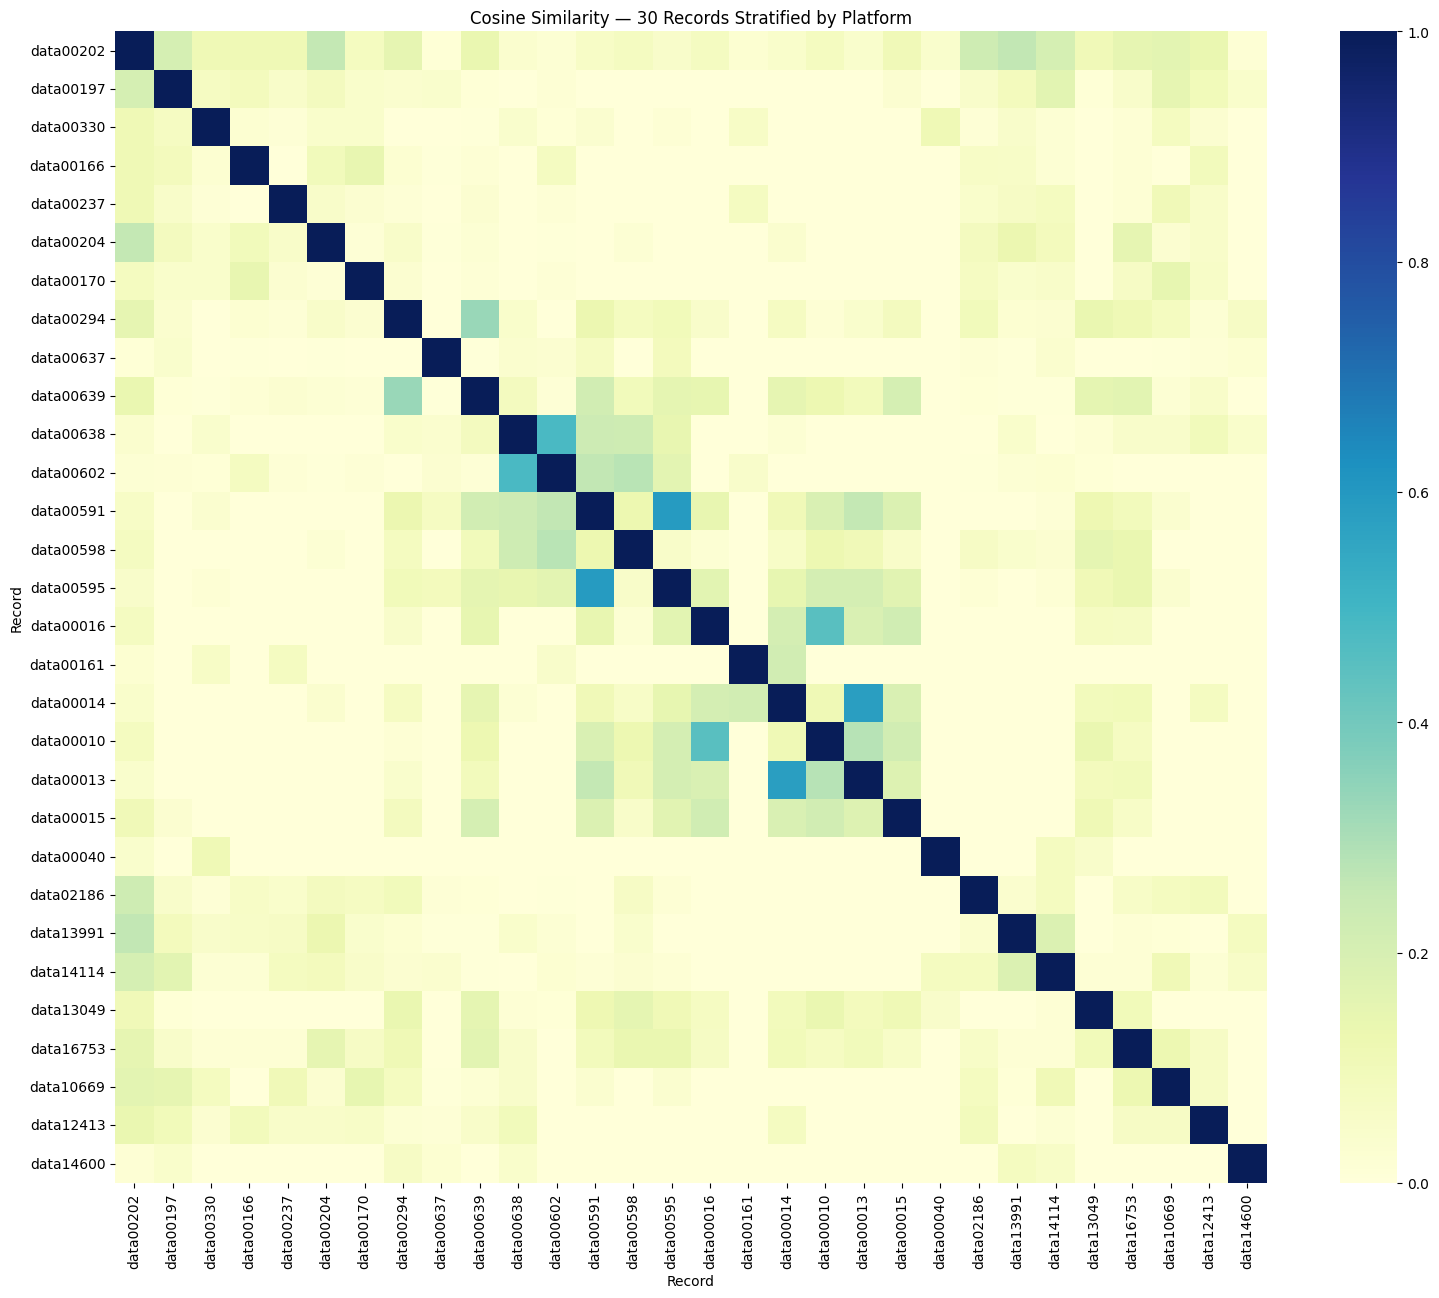

In [ ]:
cosine_subset = (
    cosine_df.loc[
        selected_ids,
        selected_ids
    ]
)

plt.figure(
    figsize=(16, 13)
)

sns.heatmap(
    cosine_subset,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Cosine Similarity — 30 Records Stratified by Platform"
)

plt.xlabel("Record")
plt.ylabel("Record")

plt.tight_layout()
plt.show()

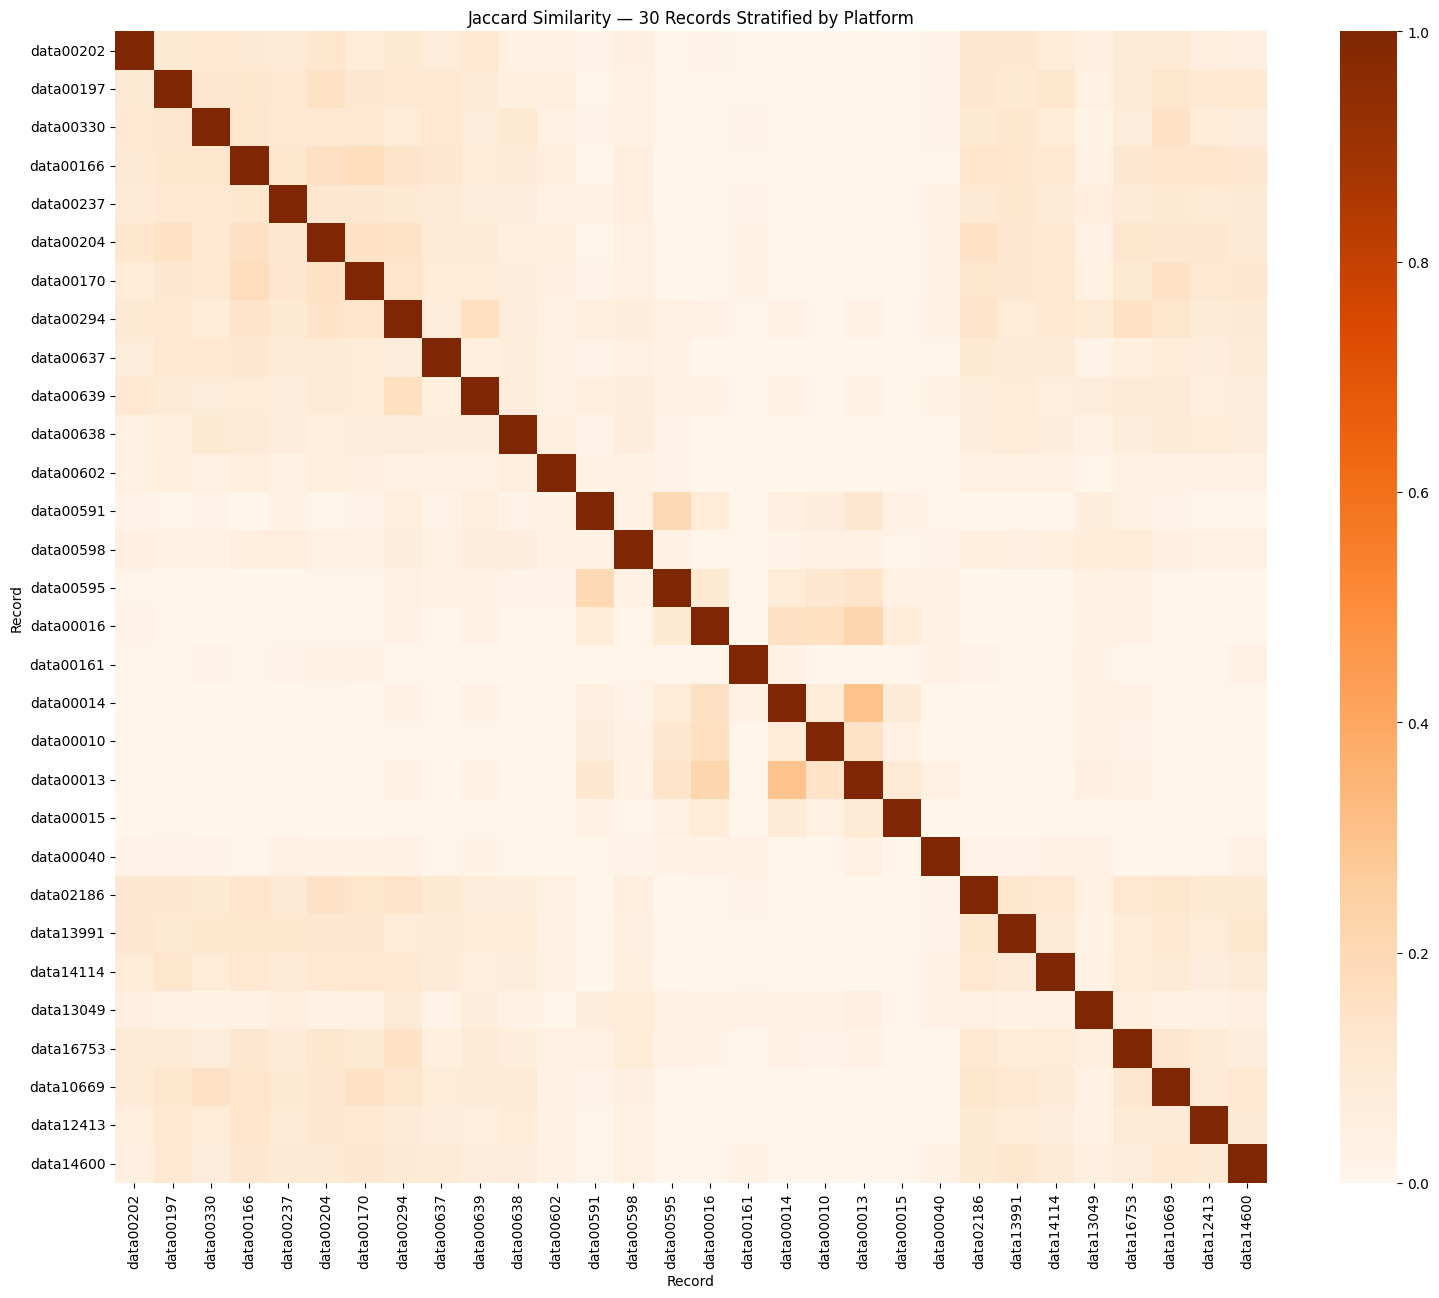

In [ ]:
jaccard_subset = (
    jaccard_df.loc[
        selected_ids,
        selected_ids
    ]
)

plt.figure(
    figsize=(16, 13)
)

sns.heatmap(
    jaccard_subset,
    cmap="Oranges",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Jaccard Similarity — 30 Records Stratified by Platform"
)

plt.xlabel("Record")
plt.ylabel("Record")

plt.tight_layout()
plt.show()

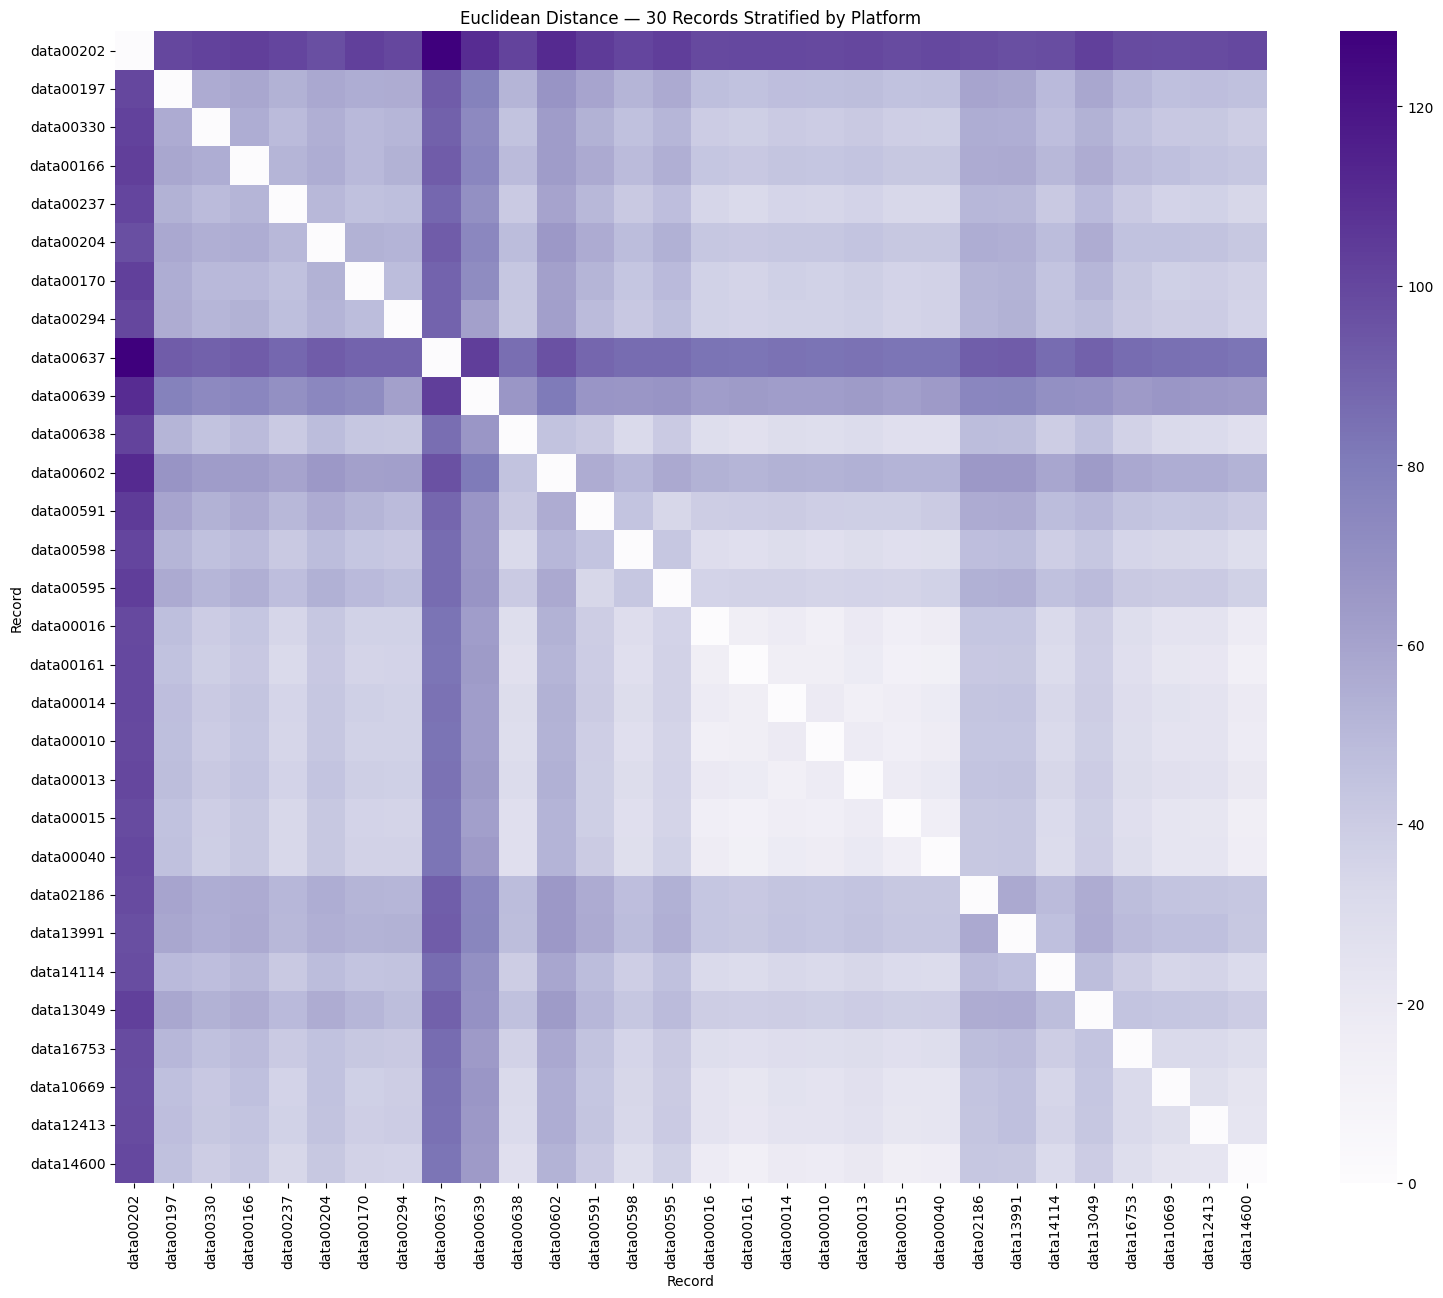

In [ ]:
euclidean_subset = (
    euclidean_df.loc[
        selected_ids,
        selected_ids
    ]
)

plt.figure(
    figsize=(16, 13)
)

sns.heatmap(
    euclidean_subset,
    cmap="Purples",
    square=True
)

plt.title(
    "Euclidean Distance — 30 Records Stratified by Platform"
)

plt.xlabel("Record")
plt.ylabel("Record")

plt.tight_layout()
plt.show()


PLATFORM ANALYSIS

Platform record counts:


,count
platform,
youtube,72
reddit,63
web,27
tiktok,18



Platforms:
['reddit', 'tiktok', 'web', 'youtube']

Platform cosine similarity:


,reddit,tiktok,web,youtube
reddit,1.000,0.118,0.104,0.271
tiktok,0.118,1.000,0.068,0.140
web,0.104,0.068,1.000,0.130
youtube,0.271,0.140,0.130,1.000



Platform Jaccard similarity:


,reddit,tiktok,web,youtube
reddit,1.000,0.132,0.052,0.189
tiktok,0.132,1.000,0.065,0.140
web,0.052,0.065,1.000,0.058
youtube,0.189,0.140,0.058,1.000



Platform Euclidean distance:


,reddit,tiktok,web,youtube
reddit,0.000,171.364,149.626,160.628
tiktok,171.364,0.000,110.383,143.938
web,149.626,110.383,0.000,116.113
youtube,160.628,143.938,116.113,0.000


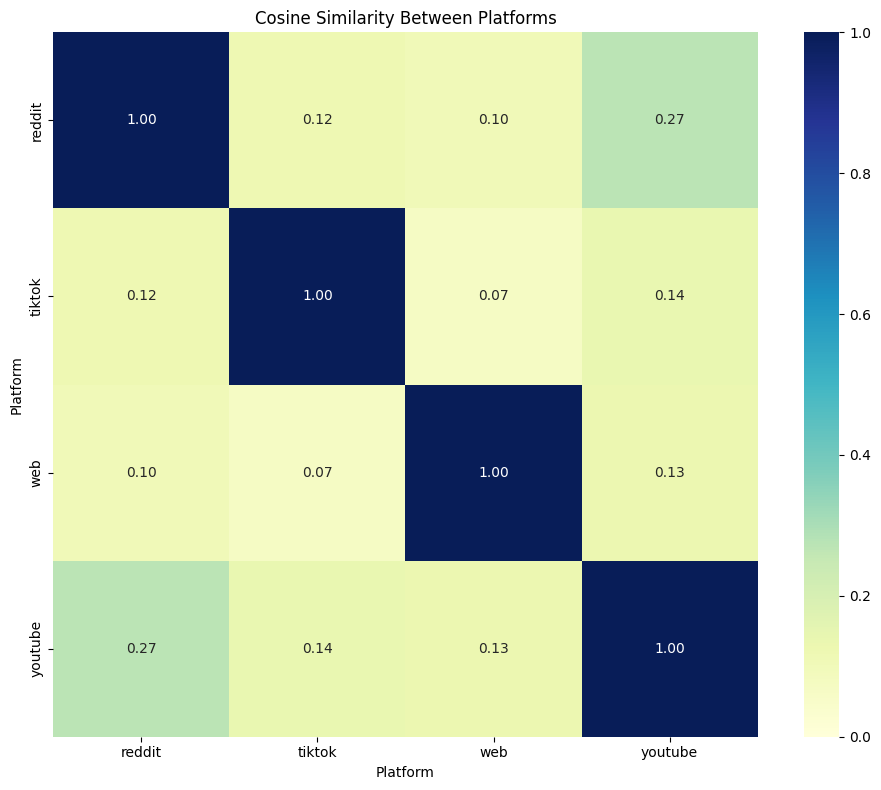

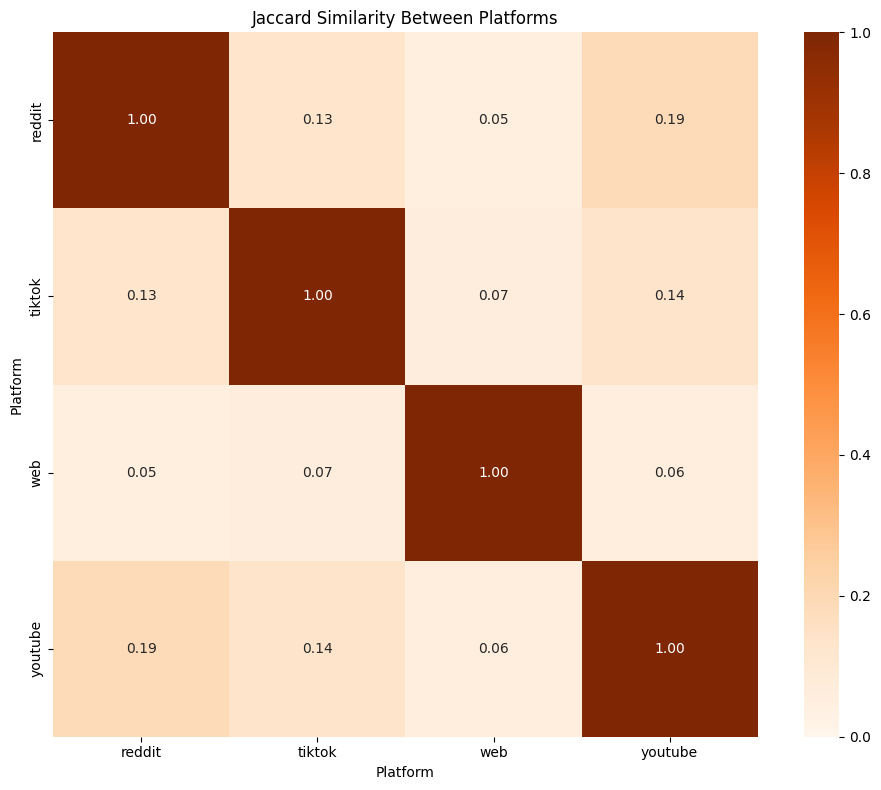

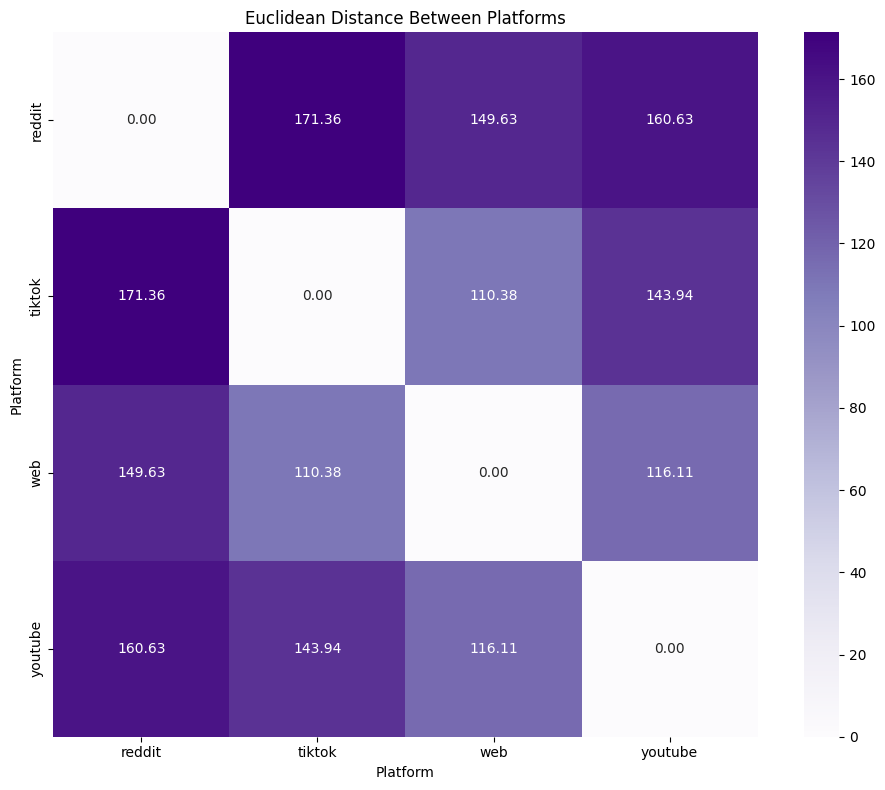

In [ ]:
print("\n" + "=" * 70)
print("PLATFORM ANALYSIS")
print("=" * 70)

print("\nPlatform record counts:")

platform_counts = (
    df["platform"]
    .value_counts()
)

display(
    platform_counts
)



platform_documents = (

    df.groupby(
        "platform"
    )["analysis_text"]

    .apply(
        lambda x:
        " ".join(x)
    )
)

print("\nPlatforms:")
print(
    platform_documents.index.tolist()
)



platform_vectorizer = TfidfVectorizer(

    lowercase=True,

    stop_words="english",

    ngram_range=(1, 2),

    norm="l2"
)

platform_tfidf = (

    platform_vectorizer

    .fit_transform(
        platform_documents
    )
)

platform_names = (
    platform_documents
    .index
    .tolist()
)



platform_cosine = (
    cosine_similarity(
        platform_tfidf
    )
)

platform_cosine_df = pd.DataFrame(

    platform_cosine,

    index=platform_names,

    columns=platform_names
)

print("\nPlatform cosine similarity:")
display(
    platform_cosine_df.round(3)
)



platform_word_sets = [

    create_word_set(text)

    for text in platform_documents
]


platform_jaccard = np.zeros(

    (
        len(platform_word_sets),
        len(platform_word_sets)
    )
)


for i in range(
    len(platform_word_sets)
):

    for j in range(
        len(platform_word_sets)
    ):

        platform_jaccard[i, j] = (
            jaccard_similarity(
                platform_word_sets[i],
                platform_word_sets[j]
            )
        )


platform_jaccard_df = pd.DataFrame(

    platform_jaccard,

    index=platform_names,

    columns=platform_names
)


print("\nPlatform Jaccard similarity:")
display(
    platform_jaccard_df.round(3)
)



platform_euclidean_vectorizer = (
    TfidfVectorizer(

        lowercase=True,

        stop_words="english",

        ngram_range=(1, 2),

        norm=None
    )
)


platform_euclidean_tfidf = (

    platform_euclidean_vectorizer

    .fit_transform(
        platform_documents
    )
)


platform_euclidean = (

    euclidean_distances(
        platform_euclidean_tfidf
    )
)


platform_euclidean_df = pd.DataFrame(

    platform_euclidean,

    index=platform_names,

    columns=platform_names
)


print("\nPlatform Euclidean distance:")
display(
    platform_euclidean_df.round(3)
)



plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    platform_cosine_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Cosine Similarity Between Platforms"
)

plt.xlabel("Platform")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    platform_jaccard_df,
    annot=True,
    fmt=".2f",
    cmap="Oranges",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Jaccard Similarity Between Platforms"
)

plt.xlabel("Platform")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    platform_euclidean_df,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    square=True
)

plt.title(
    "Euclidean Distance Between Platforms"
)

plt.xlabel("Platform")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()

In [ ]:
print("\n" + "=" * 70)
print("SEARCH KEYWORD ANALYSIS")
print("=" * 70)


keyword_counts = (
    df["keyword"]
    .value_counts(
        dropna=True
    )
)

print("\nAll search keyword counts:")
display(
    keyword_counts
)


# Keep only keywords with >= 3 records

valid_keywords = (
    keyword_counts[
        keyword_counts >= 3
    ]
    .index
    .tolist()
)

print(
    "\nNumber of Search Keywords with "
    "at least 3 records:",
    len(valid_keywords)
)


search_keyword_df = (
    df[
        df["keyword"].isin(
            valid_keywords
        )
    ]
    .copy()
)


print("\nSearch Keyword record counts:")

search_keyword_counts = (

    search_keyword_df["keyword"]

    .value_counts()

    .rename_axis(
        "search_keyword"
    )

    .reset_index(
        name="records"
    )
)

display(
    search_keyword_counts
)


SEARCH KEYWORD ANALYSIS

All search keyword counts:


,count
keyword,
philippine education,54
digital education philippines,10
education assessment philippines,8
deped philippines,8
online learning philippines,7
education curriculum philippines,5
college education philippines,5
deped teachers,5
college tuition philippines,5



Number of Search Keywords with at least 3 records: 19

Search Keyword record counts:


,search_keyword,records
0,philippine education,54
1,digital education philippines,10
2,education assessment philippines,8
3,deped philippines,8
4,online learning philippines,7
5,education curriculum philippines,5
6,college education philippines,5
7,deped teachers,5
8,college tuition philippines,5
9,blended learning philippines,5


In [ ]:
search_keyword_documents = (

    search_keyword_df

    .groupby(
        "keyword"
    )["analysis_text"]

    .apply(
        lambda x:
        " ".join(x)
    )
)


search_keyword_names = (

    search_keyword_documents

    .index

    .tolist()
)


print(
    "\nSearch Keywords used:"
)

print(
    search_keyword_names
)



Search Keywords used:
['basic education philippines', 'blended learning philippines', 'classroom problems philippines', 'college education philippines', 'college students philippines', 'college tuition philippines', 'deped philippines', 'deped schools', 'deped teachers', 'digital education philippines', 'education assessment philippines', 'education challenges philippines', 'education curriculum philippines', 'education inequality filipino students', 'online learning philippines', 'philippine education', 'philippines students', 'philippines teachers', 'school facilities philippines']


In [ ]:
search_keyword_vectorizer = (

    TfidfVectorizer(

        lowercase=True,

        stop_words="english",

        ngram_range=(1, 2),

        norm="l2"
    )
)


search_keyword_tfidf = (

    search_keyword_vectorizer

    .fit_transform(
        search_keyword_documents
    )
)

In [ ]:
search_keyword_cosine = (

    cosine_similarity(
        search_keyword_tfidf
    )
)


search_keyword_cosine_df = (

    pd.DataFrame(

        search_keyword_cosine,

        index=search_keyword_names,

        columns=search_keyword_names
    )
)


print(
    "\nSearch Keyword cosine similarity:"
)

display(
    search_keyword_cosine_df.round(3)
)



Search Keyword cosine similarity:


,basic education philippines,blended learning philippines,classroom problems philippines,college education philippines,college students philippines,college tuition philippines,deped philippines,deped schools,deped teachers,digital education philippines,education assessment philippines,education challenges philippines,education curriculum philippines,education inequality filipino students,online learning philippines,philippine education,philippines students,philippines teachers,school facilities philippines
basic education philippines,1.000,0.003,0.000,0.003,0.020,0.017,0.020,0.020,0.038,0.021,0.009,0.014,0.019,0.013,0.023,0.104,0.008,0.018,0.031
blended learning philippines,0.003,1.000,0.003,0.008,0.005,0.030,0.050,0.032,0.018,0.036,0.046,0.017,0.096,0.003,0.015,0.015,0.000,0.004,0.008
classroom problems philippines,0.000,0.003,1.000,0.000,0.000,0.003,0.005,0.006,0.004,0.024,0.007,0.000,0.003,0.004,0.005,0.054,0.000,0.006,0.007
college education philippines,0.003,0.008,0.000,1.000,0.000,0.020,0.012,0.008,0.006,0.019,0.000,0.000,0.000,0.002,0.003,0.063,0.017,0.000,0.000
college students philippines,0.020,0.005,0.000,0.000,1.000,0.000,0.005,0.000,0.000,0.015,0.016,0.018,0.011,0.004,0.015,0.043,0.000,0.000,0.005
college tuition philippines,0.017,0.030,0.003,0.020,0.000,1.000,0.034,0.048,0.075,0.030,0.024,0.022,0.051,0.013,0.053,0.085,0.037,0.004,0.039
deped philippines,0.020,0.050,0.005,0.012,0.005,0.034,1.000,0.035,0.041,0.002,0.052,0.026,0.066,0.020,0.037,0.055,0.017,0.007,0.036
deped schools,0.020,0.032,0.006,0.008,0.000,0.048,0.035,1.000,0.083,0.009,0.022,0.017,0.039,0.011,0.085,0.078,0.000,0.008,0.086
deped teachers,0.038,0.018,0.004,0.006,0.000,0.075,0.041,0.083,1.000,0.008,0.011,0.009,0.033,0.010,0.057,0.084,0.000,0.067,0.073
digital education philippines,0.021,0.036,0.024,0.019,0.015,0.030,0.002,0.009,0.008,1.000,0.026,0.021,0.021,0.017,0.057,0.113,0.052,0.019,0.068


In [ ]:
search_keyword_word_sets = [

    create_word_set(text)

    for text in search_keyword_documents
]


search_keyword_jaccard = np.zeros(

    (
        len(search_keyword_word_sets),
        len(search_keyword_word_sets)
    )
)


for i in range(
    len(search_keyword_word_sets)
):

    for j in range(
        len(search_keyword_word_sets)
    ):

        search_keyword_jaccard[i, j] = (

            jaccard_similarity(

                search_keyword_word_sets[i],

                search_keyword_word_sets[j]
            )
        )


search_keyword_jaccard_df = (

    pd.DataFrame(

        search_keyword_jaccard,

        index=search_keyword_names,

        columns=search_keyword_names
    )
)


print(
    "\nSearch Keyword Jaccard similarity:"
)

display(
    search_keyword_jaccard_df.round(3)
)


Search Keyword Jaccard similarity:


,basic education philippines,blended learning philippines,classroom problems philippines,college education philippines,college students philippines,college tuition philippines,deped philippines,deped schools,deped teachers,digital education philippines,education assessment philippines,education challenges philippines,education curriculum philippines,education inequality filipino students,online learning philippines,philippine education,philippines students,philippines teachers,school facilities philippines
basic education philippines,1.000,0.104,0.041,0.064,0.104,0.054,0.073,0.024,0.058,0.094,0.075,0.087,0.081,0.114,0.093,0.073,0.062,0.049,0.072
blended learning philippines,0.104,1.000,0.048,0.085,0.097,0.081,0.080,0.059,0.046,0.081,0.116,0.100,0.107,0.096,0.068,0.040,0.057,0.070,0.056
classroom problems philippines,0.041,0.048,1.000,0.039,0.065,0.014,0.048,0.016,0.021,0.026,0.025,0.071,0.050,0.038,0.025,0.013,0.062,0.045,0.031
college education philippines,0.064,0.085,0.039,1.000,0.066,0.050,0.062,0.032,0.048,0.049,0.075,0.082,0.027,0.047,0.050,0.027,0.064,0.040,0.026
college students philippines,0.104,0.097,0.065,0.066,1.000,0.034,0.046,0.000,0.014,0.061,0.073,0.111,0.063,0.081,0.074,0.043,0.041,0.032,0.049
college tuition philippines,0.054,0.081,0.014,0.050,0.034,1.000,0.057,0.084,0.069,0.033,0.069,0.049,0.079,0.044,0.054,0.020,0.041,0.060,0.027
deped philippines,0.073,0.080,0.048,0.062,0.046,0.057,1.000,0.061,0.078,0.032,0.070,0.088,0.070,0.060,0.059,0.031,0.059,0.037,0.062
deped schools,0.024,0.059,0.016,0.032,0.000,0.084,0.061,1.000,0.064,0.016,0.053,0.041,0.074,0.020,0.056,0.016,0.015,0.033,0.052
deped teachers,0.058,0.046,0.021,0.048,0.014,0.069,0.078,0.064,1.000,0.036,0.023,0.018,0.071,0.039,0.053,0.027,0.010,0.054,0.069
digital education philippines,0.094,0.081,0.026,0.049,0.061,0.033,0.032,0.016,0.036,1.000,0.072,0.046,0.051,0.083,0.103,0.102,0.035,0.029,0.054


In [ ]:
search_keyword_euclidean_vectorizer = (

    TfidfVectorizer(

        lowercase=True,

        stop_words="english",

        ngram_range=(1, 2),

        norm=None
    )
)


search_keyword_euclidean_tfidf = (

    search_keyword_euclidean_vectorizer

    .fit_transform(
        search_keyword_documents
    )
)


search_keyword_euclidean = (

    euclidean_distances(
        search_keyword_euclidean_tfidf
    )
)


search_keyword_euclidean_df = (

    pd.DataFrame(

        search_keyword_euclidean,

        index=search_keyword_names,

        columns=search_keyword_names
    )
)


print(
    "\nSearch Keyword Euclidean distance:"
)

display(
    search_keyword_euclidean_df.round(3)
)


Search Keyword Euclidean distance:


,basic education philippines,blended learning philippines,classroom problems philippines,college education philippines,college students philippines,college tuition philippines,deped philippines,deped schools,deped teachers,digital education philippines,education assessment philippines,education challenges philippines,education curriculum philippines,education inequality filipino students,online learning philippines,philippine education,philippines students,philippines teachers,school facilities philippines
basic education philippines,0.000,59.174,52.865,57.936,56.484,56.427,60.759,58.693,64.240,106.161,55.833,52.251,58.011,103.607,111.651,259.491,52.015,50.856,83.953
blended learning philippines,59.174,0.000,38.839,45.465,44.219,43.499,48.558,46.450,54.352,99.808,42.136,38.102,44.003,97.744,106.355,261.627,37.917,36.405,77.052
classroom problems philippines,52.865,38.839,0.000,36.969,35.325,35.061,41.920,38.793,47.763,96.844,33.696,27.507,37.707,94.031,103.344,259.670,26.844,24.662,72.390
college education philippines,57.936,45.465,36.969,0.000,42.656,42.052,48.052,45.466,53.324,99.637,41.405,36.446,44.690,97.043,106.081,259.891,35.676,34.402,76.356
college students philippines,56.484,44.219,35.325,42.656,0.000,41.059,46.987,44.330,52.359,99.187,39.628,34.498,43.095,96.379,105.188,260.353,34.255,32.630,75.446
college tuition philippines,56.427,43.499,35.061,42.052,41.059,0.000,46.142,43.089,50.372,98.714,39.285,34.212,42.051,96.030,104.048,259.141,33.461,32.344,74.418
deped philippines,60.759,48.558,41.920,48.052,46.987,46.142,0.000,48.951,55.916,102.093,44.798,41.104,47.314,98.425,106.733,260.596,40.830,39.675,77.729
deped schools,58.693,46.450,38.793,45.466,44.330,43.089,48.951,0.000,52.574,100.660,42.666,38.103,45.381,97.497,104.111,259.535,37.919,36.356,74.678
deped teachers,64.240,54.352,47.763,53.324,52.359,50.372,55.916,52.574,0.000,104.384,51.102,47.282,53.169,101.337,108.104,259.973,47.055,44.949,79.449
digital education philippines,106.161,99.808,96.844,99.637,99.187,98.714,102.093,100.660,104.384,0.000,98.390,96.722,99.855,131.276,135.174,266.573,96.006,96.090,114.135


In [ ]:
search_keyword_cosine_dissimilarity_df = (

    1 - search_keyword_cosine_df
)

search_keyword_jaccard_dissimilarity_df = (

    1 - search_keyword_jaccard_df
)

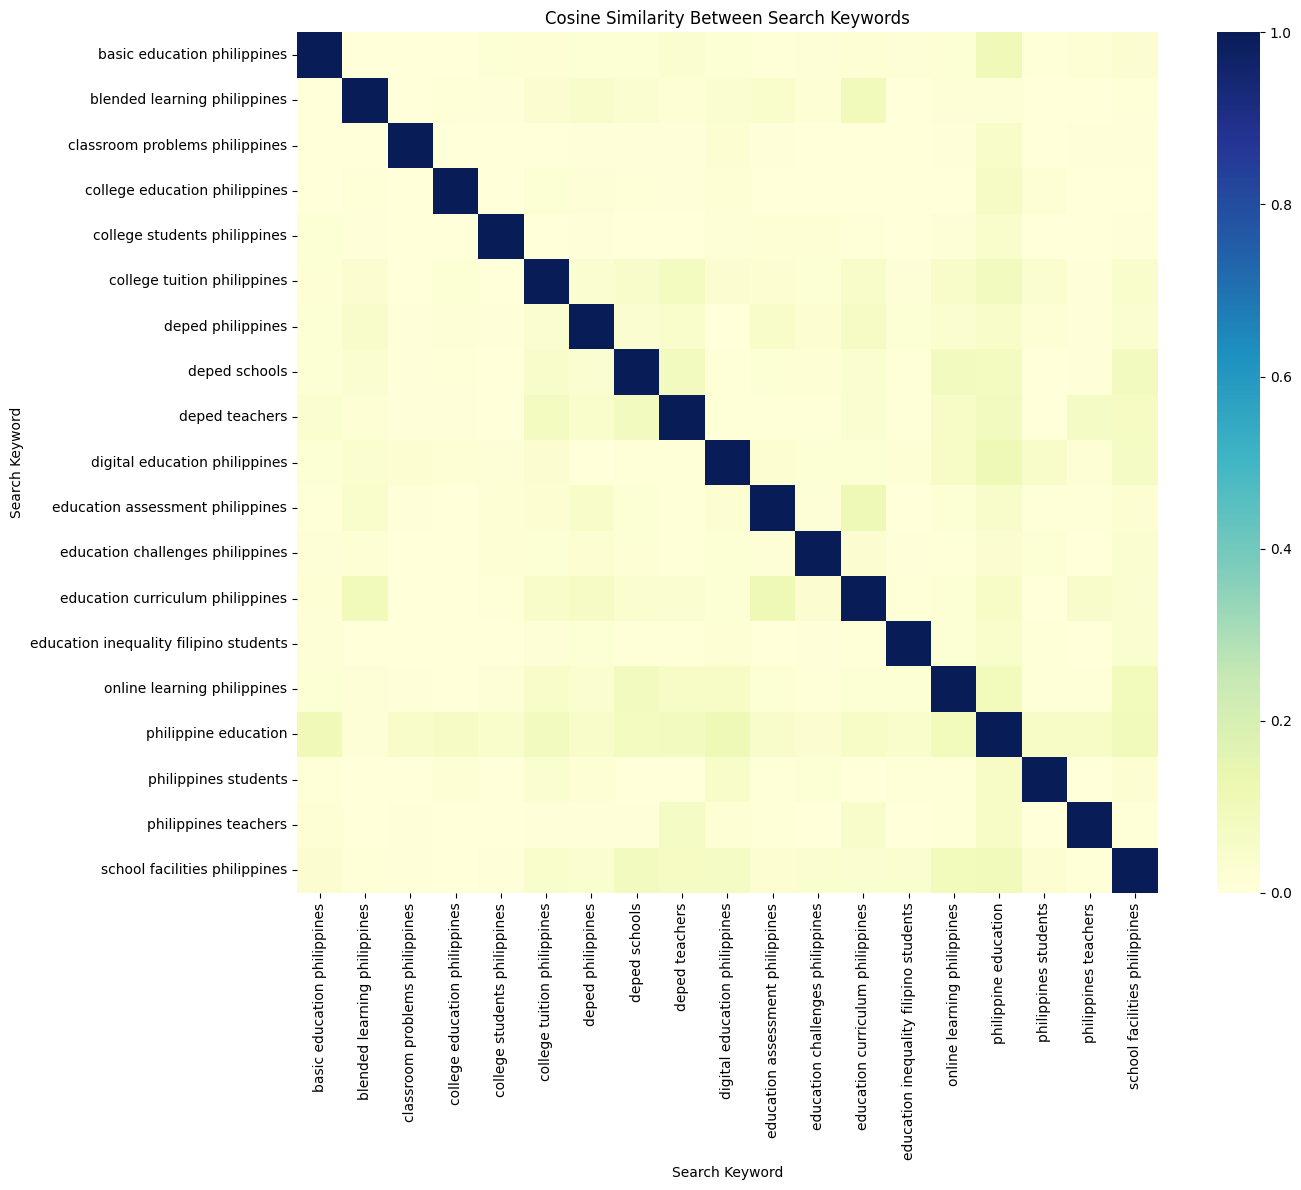

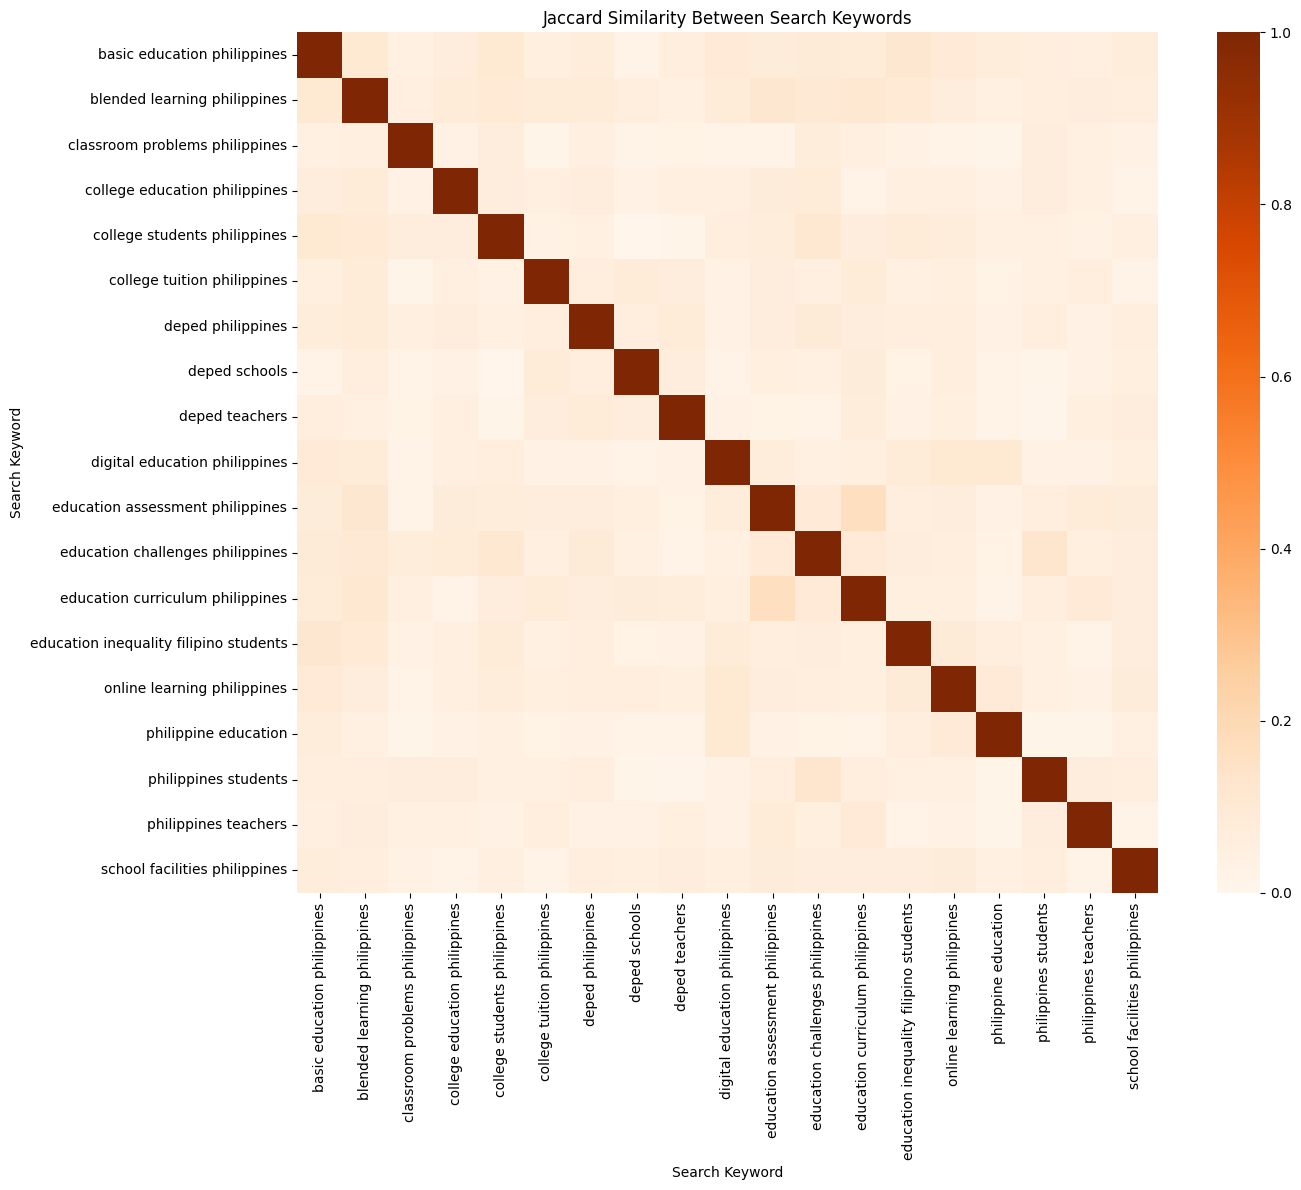

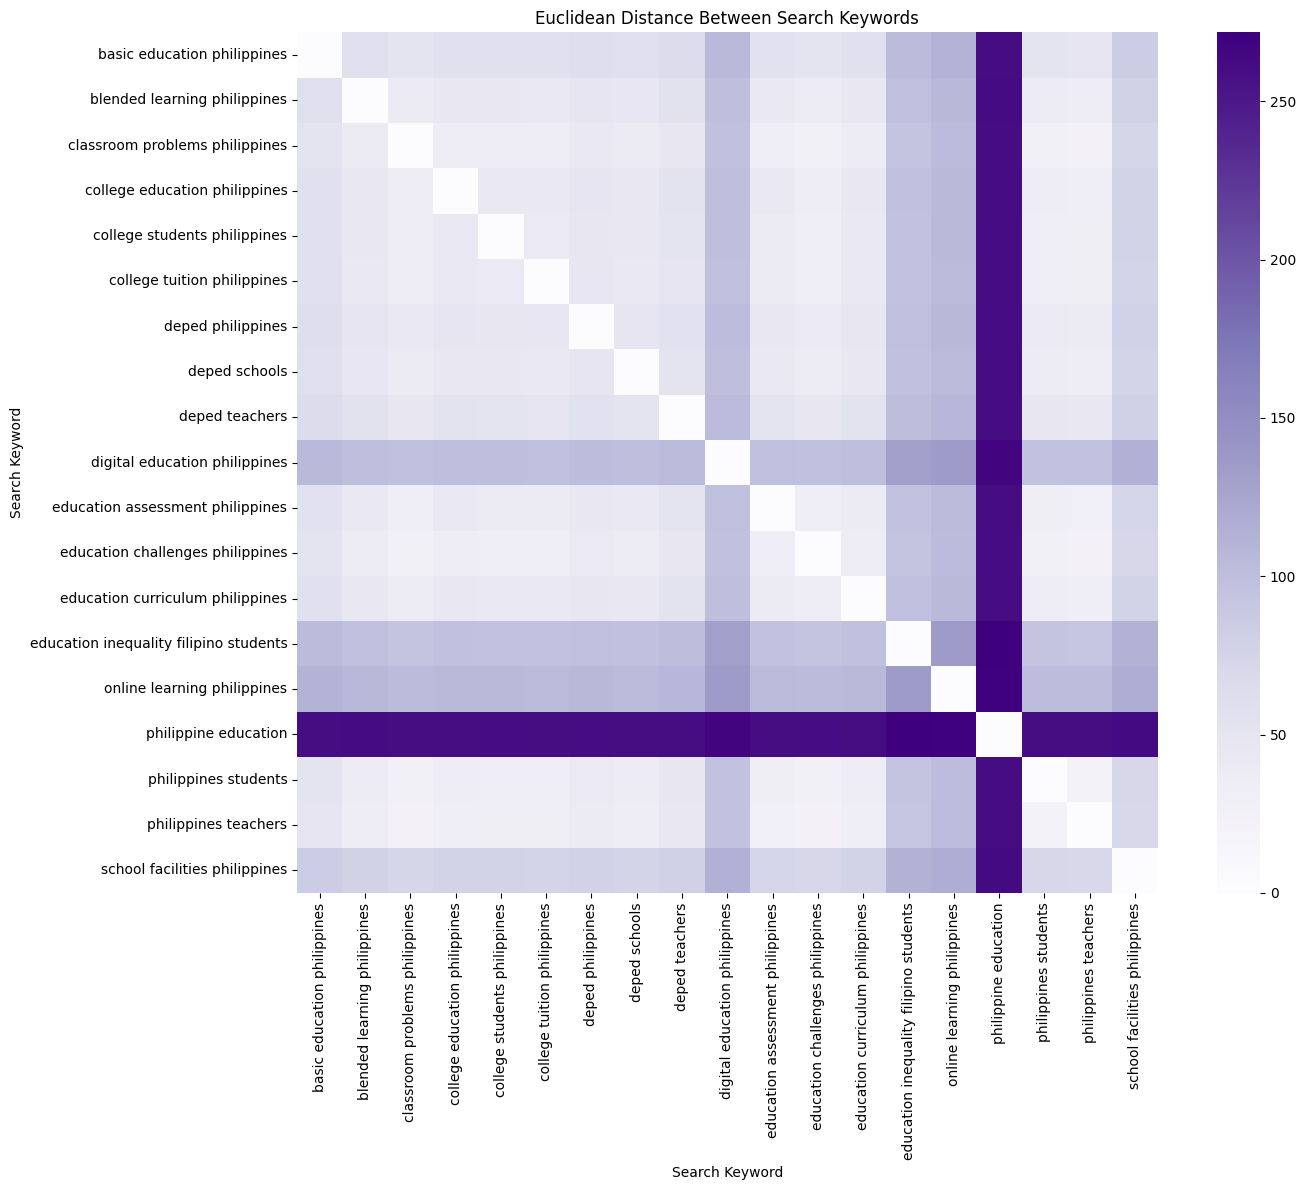

In [ ]:
plt.figure(
    figsize=(15, 12)
)

sns.heatmap(

    search_keyword_cosine_df,

    cmap="YlGnBu",

    vmin=0,

    vmax=1,

    square=True,

    annot=False
)

plt.title(
    "Cosine Similarity Between Search Keywords"
)

plt.xlabel(
    "Search Keyword"
)

plt.ylabel(
    "Search Keyword"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(15, 12)
)

sns.heatmap(

    search_keyword_jaccard_df,

    cmap="Oranges",

    vmin=0,

    vmax=1,

    square=True,

    annot=False
)

plt.title(
    "Jaccard Similarity Between Search Keywords"
)

plt.xlabel(
    "Search Keyword"
)

plt.ylabel(
    "Search Keyword"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(15, 12)
)

sns.heatmap(

    search_keyword_euclidean_df,

    cmap="Purples",

    square=True,

    annot=False
)

plt.title(
    "Euclidean Distance Between Search Keywords"
)

plt.xlabel(
    "Search Keyword"
)

plt.ylabel(
    "Search Keyword"
)

plt.tight_layout()
plt.show()


In [ ]:
print("\n" + "=" * 70)
print("TOP SEARCH KEYWORD PAIRS")
print("=" * 70)


search_keyword_pairs = get_top_pairs(

    search_keyword_cosine_df,

    "cosine_similarity",

    n=20,

    ascending=False
)

display(
    search_keyword_pairs
)


TOP SEARCH KEYWORD PAIRS


,record_1,record_2,cosine_similarity
131,digital education philippines,philippine education,0.113158
136,education assessment philippines,education curriculum philippines,0.110938
14,basic education philippines,philippine education,0.104256
167,philippine education,school facilities philippines,0.098316
28,blended learning philippines,education curriculum philippines,0.096409
164,online learning philippines,school facilities philippines,0.091038
161,online learning philippines,philippine education,0.090181
115,deped schools,school facilities philippines,0.085724
111,deped schools,online learning philippines,0.085068
89,college tuition philippines,philippine education,0.084767


In [ ]:
def compare_metrics(
    record_id_1,
    record_id_2
):

    cosine_value = (
        cosine_df.loc[
            record_id_1,
            record_id_2
        ]
    )

    jaccard_value = (
        jaccard_df.loc[
            record_id_1,
            record_id_2
        ]
    )

    return {

        "Record 1":
            record_id_1,

        "Record 2":
            record_id_2,

        "Cosine Similarity":
            cosine_value,

        "Cosine Dissimilarity":
            1 - cosine_value,

        "Jaccard Similarity":
            jaccard_value,

        "Jaccard Dissimilarity":
            1 - jaccard_value,

        "Euclidean Distance":
            euclidean_df.loc[
                record_id_1,
                record_id_2
            ]
    }


pair = compare_metrics(

    df.iloc[0]["record_id"],

    df.iloc[1]["record_id"]
)


print("\nExample record comparison:")

display(
    pd.DataFrame(
        [pair]
    ).round(4)
)


Example record comparison:


,Record 1,Record 2,Cosine Similarity,Cosine Dissimilarity,Jaccard Similarity,Jaccard Dissimilarity,Euclidean Distance
0,data00102,data16065,0.0,1.0,0.0,1.0,11.4457


In [ ]:
print("\n" + "=" * 70)
print("REMARKS AND INTERPRETATION")
print("=" * 70)


remarks = [

    (
        "Dataset",
        "The official 180-record dataset is used. "
        "The script checks that exactly 180 records are loaded."
    ),

    (
        "Text preparation",
        "The damaged lemmas column is not used. "
        "Original text/title fields are used instead."
    ),

    (
        "Comments",
        "Reddit and YouTube comments are compared using "
        "comment text only. Parent titles are excluded."
    ),

    (
        "Articles and Reddit posts",
        "Articles and Reddit posts use their own titles "
        "rather than parent titles."
    ),

    (
        "Duplicate candidate",
        "data00396 and data00327 no longer produce the old "
        "0.92 similarity after title leakage is removed. "
        "The corrected values should be used for manual verification."
    ),

    (
        "Reddit grouping",
        "Reddit public post page and Reddit public search "
        "are collection methods, so they are merged under "
        "the Reddit platform."
    ),

    (
        "Search Keyword",
        "The keyword field represents search keywords rather "
        "than discovered topics. Only keywords with at least "
        "3 records are included in the group analysis."
    ),

    (
        "Uneven platform sizes",
        "Platform comparisons use group-level TF-IDF centroids "
        "for cosine and Euclidean calculations. Jaccard uses "
        "average pairwise similarity."
    ),

    (
        "Euclidean distance",
        "Euclidean distance uses unnormalized TF-IDF "
        "(norm=None), so it is not simply a restatement "
        "of cosine distance on normalized vectors."
    ),

    (
        "Dissimilarity",
        "Cosine and Jaccard dissimilarity are calculated as "
        "1 minus similarity."
    ),

    (
        "Most dissimilar records",
        "An arbitrary bottom-20 table is not reported because "
        "many record pairs have exactly zero similarity. "
        "Instead, average similarity and the percentage of "
        "zero-similarity pairs are reported."
    ),

    (
        "Record heatmap",
        "The 30-record heatmap is selected across platforms "
        "rather than simply taking the 30 longest records. "
        "This prevents articles from dominating the visualization."
    ),

    (
        "Search Keyword heatmap",
        "Numerical annotations are removed because the "
        "keyword matrices are too crowded to read clearly."
    )
]


remarks_df = pd.DataFrame(

    remarks,

    columns=[
        "Item",
        "Interpretation"
    ]
)


display(
    remarks_df
)


REMARKS AND INTERPRETATION


,Item,Interpretation
0,Dataset,The official 180-record dataset is used. The script checks that exactly 180 records are loaded.
1,Text preparation,The damaged lemmas column is not used. Original text/title fields are used instead.
2,Comments,Reddit and YouTube comments are compared using comment text only. Parent titles are excluded.
3,Articles and Reddit posts,Articles and Reddit posts use their own titles rather than parent titles.
4,Duplicate candidate,data00396 and data00327 no longer produce the old 0.92 similarity after title leakage is removed...
5,Reddit grouping,"Reddit public post page and Reddit public search are collection methods, so they are merged unde..."
6,Search Keyword,The keyword field represents search keywords rather than discovered topics. Only keywords with a...
7,Uneven platform sizes,Platform comparisons use group-level TF-IDF centroids for cosine and Euclidean calculations. Jac...
8,Euclidean distance,"Euclidean distance uses unnormalized TF-IDF (norm=None), so it is not simply a restatement of co..."
9,Dissimilarity,Cosine and Jaccard dissimilarity are calculated as 1 minus similarity.


In [ ]:
print("\n" + "=" * 70)
print("SAVING RESULTS")
print("=" * 70)


# Record-level matrices

cosine_df.to_csv(
    "record_cosine_similarity.csv"
)

cosine_dissimilarity_df.to_csv(
    "record_cosine_dissimilarity.csv"
)

jaccard_df.to_csv(
    "record_jaccard_similarity.csv"
)

jaccard_dissimilarity_df.to_csv(
    "record_jaccard_dissimilarity.csv"
)

euclidean_df.to_csv(
    "record_euclidean_distance.csv"
)


# Summary

similarity_summary.to_csv(
    "record_similarity_summary.csv",
    index=False
)


# Top pairs

top_cosine_detailed.to_csv(
    "top20_cosine_pairs.csv",
    index=False
)

top_jaccard_detailed.to_csv(
    "top20_jaccard_pairs.csv",
    index=False
)

top_euclidean_detailed.to_csv(
    "top20_euclidean_pairs.csv",
    index=False
)


# Duplicate

duplicate_check.to_csv(
    "duplicate_candidate_check.csv",
    index=False
)


# Platform

platform_counts.to_csv(
    "platform_counts.csv"
)

platform_cosine_df.to_csv(
    "platform_cosine_similarity.csv"
)

platform_jaccard_df.to_csv(
    "platform_jaccard_similarity.csv"
)

platform_euclidean_df.to_csv(
    "platform_euclidean_distance.csv"
)


# Search Keyword

search_keyword_counts.to_csv(
    "search_keyword_counts.csv",
    index=False
)

search_keyword_cosine_df.to_csv(
    "search_keyword_cosine_similarity.csv"
)

search_keyword_jaccard_df.to_csv(
    "search_keyword_jaccard_similarity.csv"
)

search_keyword_euclidean_df.to_csv(
    "search_keyword_euclidean_distance.csv"
)

search_keyword_cosine_dissimilarity_df.to_csv(
    "search_keyword_cosine_dissimilarity.csv"
)

search_keyword_jaccard_dissimilarity_df.to_csv(
    "search_keyword_jaccard_dissimilarity.csv"
)


# Remarks

remarks_df.to_csv(
    "remarks.csv",
    index=False
)


# Record overview

df[
    [
        "record_id",
        "record_type",
        "platform",
        "source_name",
        "keyword",
        "title",
        "analysis_text",
        "text_length"
    ]
].to_csv(
    "record_text_overview.csv",
    index=False
)


SAVING RESULTS


In [ ]:
print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(
    "\nRecords analyzed:",
    len(df)
)

print(
    "\nPlatform counts:"
)

display(
    df["platform"]
    .value_counts()
)


print(
    "\nAverage Cosine Similarity:",
    round(
        cosine_values.mean(),
        4
    )
)

print(
    "Cosine zero-similarity pairs:",
    round(
        (
            cosine_values == 0
        ).mean() * 100,
        2
    ),
    "%"
)

print(
    "\nAverage Jaccard Similarity:",
    round(
        jaccard_values.mean(),
        4
    )
)

print(
    "Jaccard zero-similarity pairs:",
    round(
        (
            jaccard_values == 0
        ).mean() * 100,
        2
    ),
    "%"
)

print(
    "\nAverage Euclidean Distance:",
    round(
        euclidean_values.mean(),
        4
    )
)

print(
    "\nSearch Keywords retained:",
    len(valid_keywords)
)

print(
    "\nDuplicate check:"
)

display(
    duplicate_check.round(4)
)


print("\n" + "=" * 70)
print("CORRECTED ANALYSIS COMPLETED")
print("=" * 70)


FINAL SUMMARY

Records analyzed: 180

Platform counts:


,count
platform,
youtube,72
reddit,63
web,27
tiktok,18



Average Cosine Similarity: 0.0216
Cosine zero-similarity pairs: 80.07 %

Average Jaccard Similarity: 0.0196
Jaccard zero-similarity pairs: 56.76 %

Average Euclidean Distance: 24.0211

Search Keywords retained: 19

Duplicate check:


,record_1,record_2,cosine_similarity,cosine_dissimilarity,jaccard_similarity,jaccard_dissimilarity,note
0,data00396,data00327,0.0,1.0,0.0,1.0,Old 0.92 result was caused by title leakage. Corrected analysis compares the actual record text.



CORRECTED ANALYSIS COMPLETED
